# Karnataka MGNREGA Work Demand Analysis (FY 2024–25)
  
**Dataset:** District-wise monthly household demand for work under MGNREGA in Karnataka, FY 2024–25.

## Project objective
Analyse how household demand for MGNREGA work varies across months and districts in Karnataka.


## 1. Upload the dataset

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Karnataka_MGNREGA_Work_Demand_FY2024_25_Clean.csv to Karnataka_MGNREGA_Work_Demand_FY2024_25_Clean.csv


## 2. Import libraries and load the dataset

** What does the district-wise monthly MGNREGA work-demand dataset look like?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Karnataka_MGNREGA_Work_Demand_FY2024_25_Clean.csv')

df.head()

,State,Financial_Year,District,Month_Number_FY,Month,Households_Demanded
0,Karnataka,2024-2025,Bagalkote,1,April,51772
1,Karnataka,2024-2025,Bagalkote,2,May,55264
2,Karnataka,2024-2025,Bagalkote,3,June,51842
3,Karnataka,2024-2025,Bagalkote,4,July,49210
4,Karnataka,2024-2025,Bagalkote,5,August,32062


## 3. Check data quality and structure

** Is the dataset complete and structurally suitable for analysis?

In [3]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDistricts:", df["District"].nunique())

Dataset shape: (372, 6)

Data types:
State                  object
Financial_Year         object
District               object
Month_Number_FY         int64
Month                  object
Households_Demanded     int64
dtype: object

Missing values:
State                  0
Financial_Year         0
District               0
Month_Number_FY        0
Month                  0
Households_Demanded    0
dtype: int64

Duplicate rows: 0

Districts: 31


## 4. Calculate monthly household demand

** How many households demanded MGNREGA work in each month across Karnataka during FY 2024–25?


In [4]:
monthly_demand = (
    df.groupby("Month_Number_FY")["Households_Demanded"]
    .sum()
    .reset_index()
)

monthly_demand = monthly_demand.merge(
    df[["Month_Number_FY", "Month"]].drop_duplicates(),
    on="Month_Number_FY"
)

monthly_demand = monthly_demand.sort_values("Month_Number_FY")

print(monthly_demand[["Month", "Households_Demanded"]])

        Month  Households_Demanded
0       April              1301689
1         May              1528799
2        June              1280907
3        July               980423
4      August               633502
5   September               647801
6     October               568443
7    November               620541
8    December               668827
9     January               741859
10   February               772913
11      March              1148361


## 5. Visualise monthly work demand

**Business question What is the month-wise pattern of household demand for MGNREGA work?

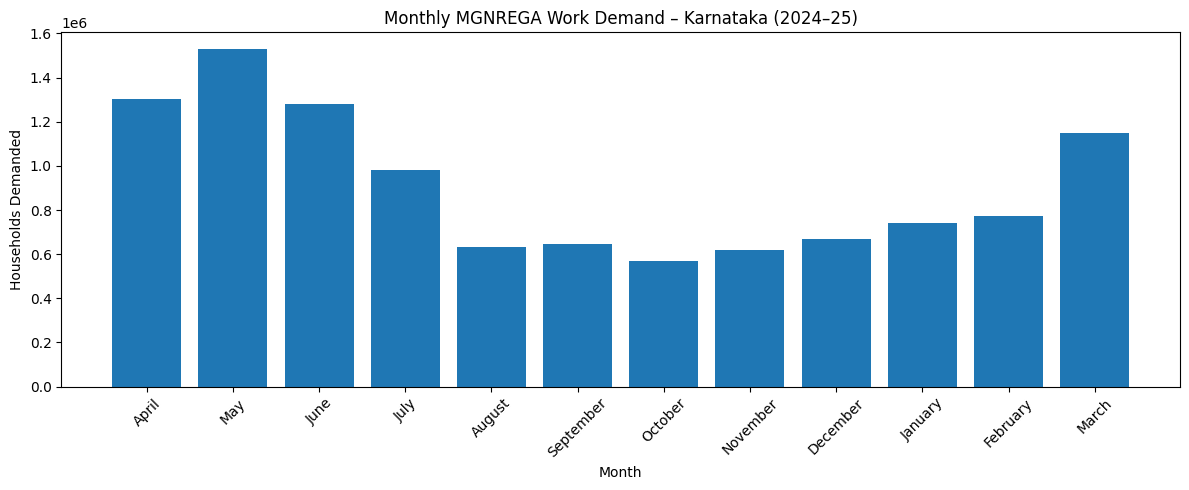

In [5]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_demand["Month"],
    monthly_demand["Households_Demanded"]
)

plt.title("Monthly MGNREGA Work Demand – Karnataka (2024–25)")
plt.xlabel("Month")
plt.ylabel("Households Demanded")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Rank districts by cumulative household demand

** Which districts recorded the highest and lowest cumulative household demand during FY 2024–25?

In [6]:
district_demand = (
    df.groupby("District")["Households_Demanded"]
    .sum()
    .sort_values(ascending=False)
)

print("TOP 10 DISTRICTS")
print(district_demand.head(10))

print("\nBOTTOM 10 DISTRICTS")
print(district_demand.tail(10).sort_values())

TOP 10 DISTRICTS
District
Belagavi        1099019
Raichur          786915
Koppal           652137
Kalaburagi       626437
Bidar            579475
Chitradurga      557854
Tumakuru         525685
Yadgir           466679
Bagalkote        462780
Vijayanagara     449199
Name: Households_Demanded, dtype: int64

BOTTOM 10 DISTRICTS
District
Bengaluru             5491
Kodagu               31975
Udupi                50176
Dakshina Kannada     69370
Bengaluru Rural     125952
Uttara Kannada      161694
Dharwar             185471
Mysuru              192649
Chikkamagaluru      212937
Davanagere          226744
Name: Households_Demanded, dtype: int64


## 7. Visualise the ten highest-demand districts

** How do the ten highest-demand districts compare with one another?

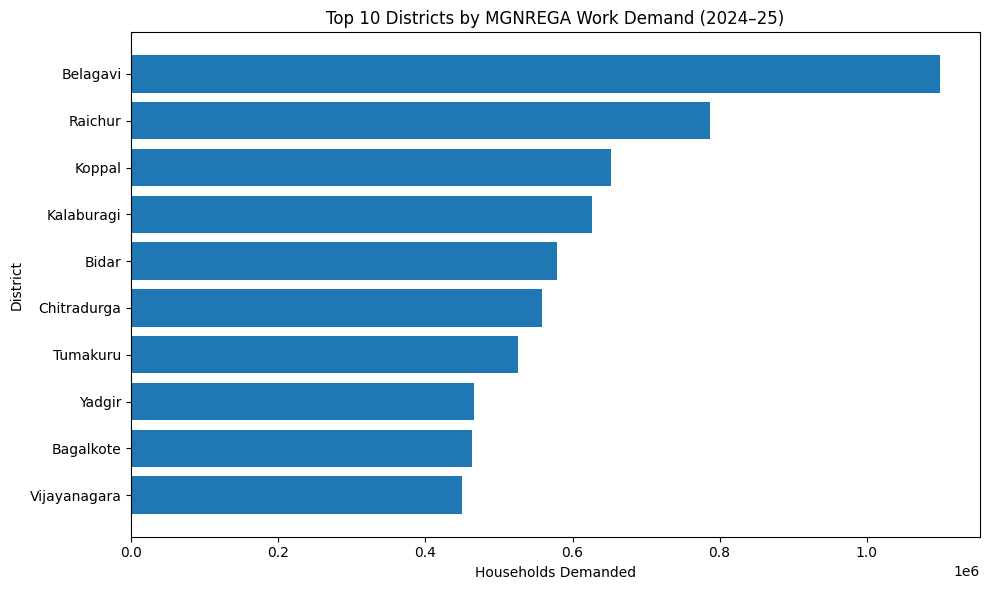

In [7]:
top_10 = district_demand.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(top_10.index, top_10.values)

plt.title("Top 10 Districts by MGNREGA Work Demand (2024–25)")
plt.xlabel("Households Demanded")
plt.ylabel("District")

plt.tight_layout()
plt.show()

## 8. Calculate month-on-month percentage change

** By what percentage did household demand increase or decrease compared with the previous month?

In [8]:
monthly_demand["MoM_Change_%"] = (
    monthly_demand["Households_Demanded"].pct_change() * 100
)

print(
    monthly_demand[
        ["Month", "Households_Demanded", "MoM_Change_%"]
    ].round(2)
)

        Month  Households_Demanded  MoM_Change_%
0       April              1301689           NaN
1         May              1528799         17.45
2        June              1280907        -16.21
3        July               980423        -23.46
4      August               633502        -35.38
5   September               647801          2.26
6     October               568443        -12.25
7    November               620541          9.17
8    December               668827          7.78
9     January               741859         10.92
10   February               772913          4.19
11      March              1148361         48.58
